# Experiment 9: Markov Model and Reinforcement Learning

**Aim:** To understand Markov models and implement basic reinforcement learning techniques using Python.

## Exercise 1: Markov Model
Define states and transition probabilities for a simple environment. Simulate state changes, visualize the results, and study the system's long-term behavior.

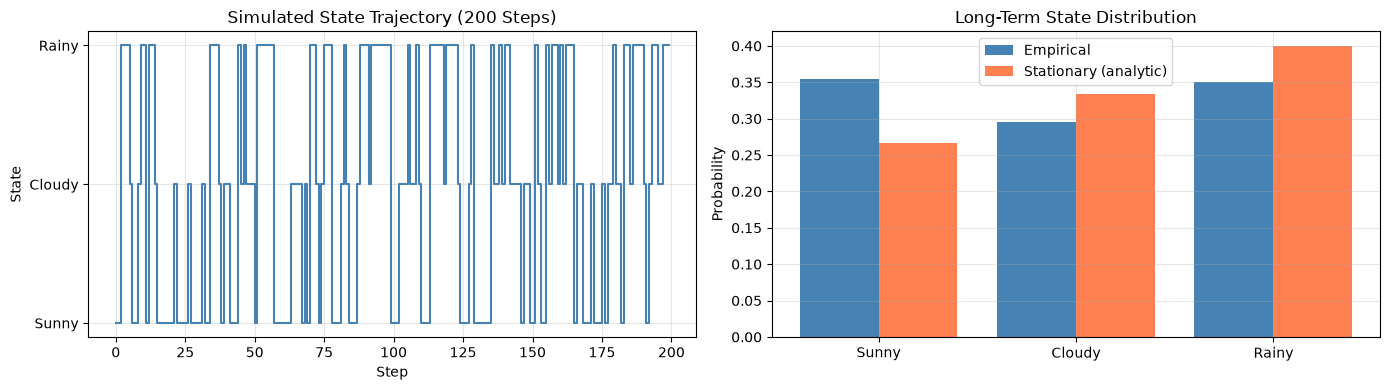

Transition Matrix P:
[[0.6 0.3 0.1]
 [0.2 0.4 0.4]
 [0.1 0.3 0.6]]

Analytic Stationary Distribution: {'Sunny': np.float64(0.2667), 'Cloudy': np.float64(0.3333), 'Rainy': np.float64(0.4)}
Empirical Distribution:           {'Sunny': np.float64(0.355), 'Cloudy': np.float64(0.295), 'Rainy': np.float64(0.35)}


In [1]:
import numpy as np
import matplotlib.pyplot as plt

# States: Sunny, Cloudy, Rainy
states = ['Sunny', 'Cloudy', 'Rainy']

# Transition probability matrix  P[i][j] = P(state_j | state_i)
P = np.array([
    [0.6, 0.3, 0.1],   # From Sunny
    [0.2, 0.4, 0.4],   # From Cloudy
    [0.1, 0.3, 0.6],   # From Rainy
])

np.random.seed(42)
n_steps = 200
current_state = 0        # Start at Sunny
trajectory = [current_state]

for _ in range(n_steps - 1):
    current_state = np.random.choice(len(states), p=P[current_state])
    trajectory.append(current_state)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# --- Plot trajectory ---
axes[0].step(range(n_steps), trajectory, where='post', color='steelblue')
axes[0].set_yticks([0, 1, 2])
axes[0].set_yticklabels(states)
axes[0].set_xlabel('Step')
axes[0].set_ylabel('State')
axes[0].set_title('Simulated State Trajectory (200 Steps)')
axes[0].grid(True, alpha=0.3)

# --- Long-term behavior: Stationary distribution ---
counts = np.bincount(trajectory, minlength=len(states)) / n_steps
evals, evecs = np.linalg.eig(P.T)
stationary = np.real(evecs[:, np.isclose(evals, 1)][:, 0])
stationary /= stationary.sum()

x = np.arange(len(states))
axes[1].bar(x - 0.2, counts, 0.4, label='Empirical', color='steelblue')
axes[1].bar(x + 0.2, stationary, 0.4, label='Stationary (analytic)', color='coral')
axes[1].set_xticks(x)
axes[1].set_xticklabels(states)
axes[1].set_ylabel('Probability')
axes[1].set_title('Long-Term State Distribution')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print('Transition Matrix P:')
print(P)
print(f'\nAnalytic Stationary Distribution: {dict(zip(states, stationary.round(4)))}')
print(f'Empirical Distribution:           {dict(zip(states, counts.round(4)))}')


## Exercise 2: Reward-Based Decision-Making
Define actions and assign rewards or penalties. Observe how changing rewards affects the agent's decisions.

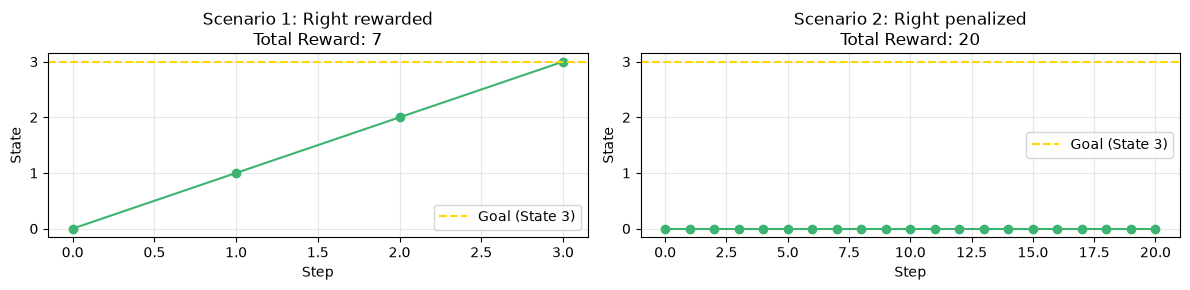

Scenario 1 - Path: [0, 1, 2, 3] | Total Reward: 7
Scenario 2 - Path: [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0] | Total Reward: 20


In [2]:
# Simple Grid World: 4 cells in a row, states 0-3, Goal = state 3
# Actions: Left(0), Right(1)

def get_next_state(state, action, n_states=4):
    if action == 0:   # Left
        return max(0, state - 1)
    else:             # Right
        return min(n_states - 1, state + 1)

def greedy_policy(state, reward_table):
    return int(np.argmax([reward_table[state][a] for a in [0, 1]]))

def simulate_greedy(reward_table, start=0, goal=3, max_steps=20):
    state = start
    path = [state]
    total_reward = 0
    for _ in range(max_steps):
        action = greedy_policy(state, reward_table)
        reward = reward_table[state][action]
        state = get_next_state(state, action)
        total_reward += reward
        path.append(state)
        if state == goal:
            break
    return path, total_reward

# Scenario 1: Reward for moving right
reward_table_1 = {
    0: {0: -1, 1: +1},
    1: {0: -1, 1: +1},
    2: {0: -1, 1: +5},
    3: {0:  0, 1:  0},
}

# Scenario 2: Penalty for moving right (agent prefers left)
reward_table_2 = {
    0: {0: +1, 1: -1},
    1: {0: +1, 1: -1},
    2: {0: +1, 1: -5},
    3: {0:  0, 1:  0},
}

path1, rew1 = simulate_greedy(reward_table_1)
path2, rew2 = simulate_greedy(reward_table_2)

fig, axes = plt.subplots(1, 2, figsize=(12, 3))
for ax, path, rew, title in zip(
    axes, [path1, path2], [rew1, rew2],
    ['Scenario 1: Right rewarded', 'Scenario 2: Right penalized']
):
    ax.plot(range(len(path)), path, marker='o', color='mediumseagreen')
    ax.axhline(y=3, color='gold', linestyle='--', label='Goal (State 3)')
    ax.set_xlabel('Step')
    ax.set_ylabel('State')
    ax.set_title(f'{title}\nTotal Reward: {rew}')
    ax.set_yticks([0, 1, 2, 3])
    ax.legend()
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print('Scenario 1 - Path:', path1, '| Total Reward:', rew1)
print('Scenario 2 - Path:', path2, '| Total Reward:', rew2)


## Exercise 3: Q-Learning
Implement Q-learning to learn the best policy. Visualize Q-values and plot a learning curve of cumulative rewards.

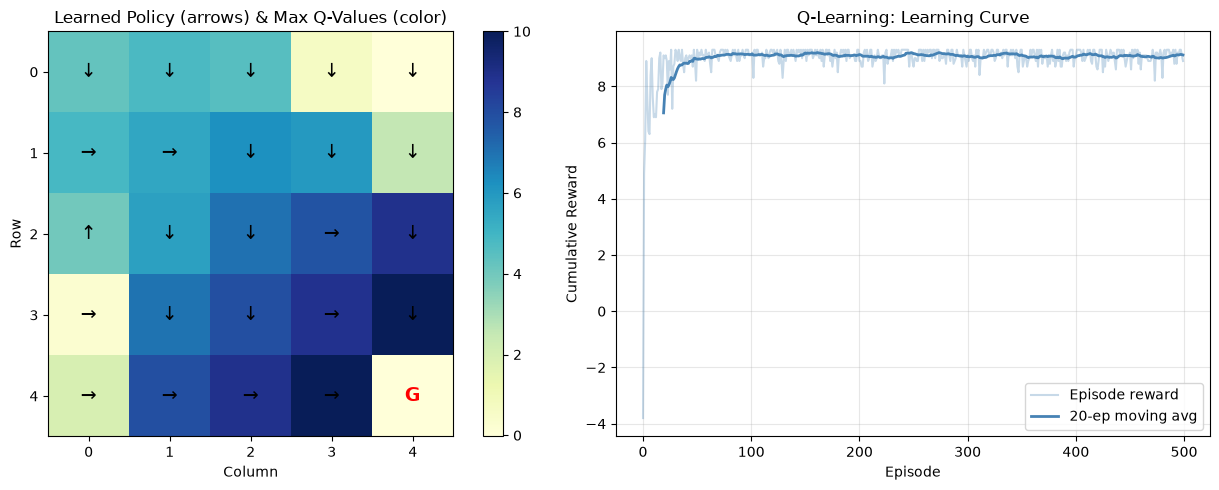

Q-learning complete. Goal state: (4, 4)
Final avg reward (last 50 eps): 9.076


In [3]:
# 5x5 Grid World, start=(0,0), goal=(4,4)
# Actions: Up(0), Down(1), Left(2), Right(3)

GRID_SIZE = 5
GOAL = (4, 4)
ACTIONS = [(-1, 0), (1, 0), (0, -1), (0, 1)]
ARROWS = ['↑', '↓', '←', '→']

def step(state, action):
    r, c = state
    dr, dc = ACTIONS[action]
    nr = max(0, min(GRID_SIZE - 1, r + dr))
    nc = max(0, min(GRID_SIZE - 1, c + dc))
    next_state = (nr, nc)
    if next_state == GOAL:
        return next_state, 10.0, True
    return next_state, -0.1, False

def q_learning(alpha=0.1, gamma=0.9, epsilon=0.2, n_episodes=500):
    Q = np.zeros((GRID_SIZE, GRID_SIZE, len(ACTIONS)))
    cumulative_rewards = []
    for _ in range(n_episodes):
        state = (0, 0)
        done = False
        ep_reward = 0
        while not done:
            r, c = state
            if np.random.rand() < epsilon:
                action = np.random.randint(len(ACTIONS))
            else:
                action = int(np.argmax(Q[r, c]))
            next_state, reward, done = step(state, action)
            nr, nc = next_state
            Q[r, c, action] += alpha * (reward + gamma * np.max(Q[nr, nc]) - Q[r, c, action])
            state = next_state
            ep_reward += reward
        cumulative_rewards.append(ep_reward)
    return Q, cumulative_rewards

np.random.seed(0)
Q, cum_rewards = q_learning()

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Q-value heatmap with policy arrows
max_Q = np.max(Q, axis=2)
best_actions = np.argmax(Q, axis=2)
im = axes[0].imshow(max_Q, cmap='YlGnBu')
plt.colorbar(im, ax=axes[0])
for r in range(GRID_SIZE):
    for c in range(GRID_SIZE):
        if (r, c) == GOAL:
            axes[0].text(c, r, 'G', ha='center', va='center',
                         fontsize=14, fontweight='bold', color='red')
        else:
            axes[0].text(c, r, ARROWS[best_actions[r, c]],
                         ha='center', va='center', fontsize=14)
axes[0].set_title('Learned Policy (arrows) & Max Q-Values (color)')
axes[0].set_xlabel('Column')
axes[0].set_ylabel('Row')

# Learning curve
window = 20
smoothed = np.convolve(cum_rewards, np.ones(window) / window, mode='valid')
axes[1].plot(cum_rewards, alpha=0.3, color='steelblue', label='Episode reward')
axes[1].plot(range(window - 1, len(cum_rewards)), smoothed,
             color='steelblue', linewidth=2, label=f'{window}-ep moving avg')
axes[1].set_xlabel('Episode')
axes[1].set_ylabel('Cumulative Reward')
axes[1].set_title('Q-Learning: Learning Curve')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print('Q-learning complete. Goal state:', GOAL)
print('Final avg reward (last 50 eps):', round(np.mean(cum_rewards[-50:]), 3))


## Exercise 4: Exploration vs. Exploitation
Try different epsilon values and observe how they affect the agent's learning.

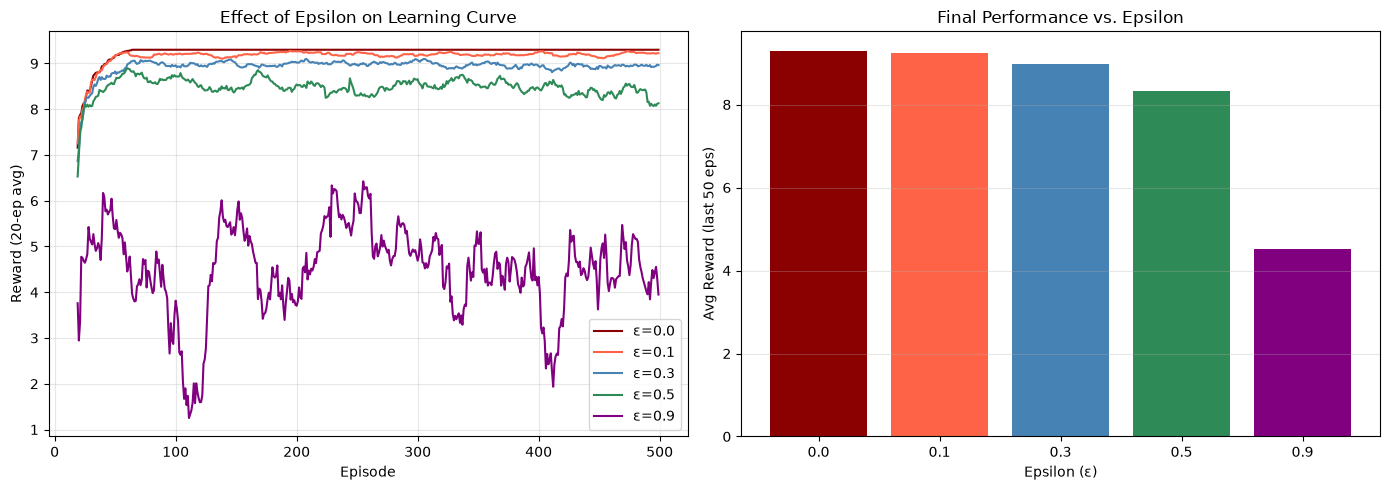

ε=0.0  →  Avg reward (last 50 eps): 9.300
ε=0.1  →  Avg reward (last 50 eps): 9.232
ε=0.3  →  Avg reward (last 50 eps): 8.966
ε=0.5  →  Avg reward (last 50 eps): 8.316
ε=0.9  →  Avg reward (last 50 eps): 4.524


In [4]:
epsilons = [0.0, 0.1, 0.3, 0.5, 0.9]
colors   = ['darkred', 'tomato', 'steelblue', 'seagreen', 'purple']
n_episodes = 500
window = 20

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
avg_rewards = []

for eps, color in zip(epsilons, colors):
    np.random.seed(0)
    _, rewards = q_learning(epsilon=eps, n_episodes=n_episodes)
    smoothed = np.convolve(rewards, np.ones(window) / window, mode='valid')
    axes[0].plot(range(window - 1, n_episodes), smoothed,
                 label=f'ε={eps}', color=color)
    avg_rewards.append(np.mean(rewards[-50:]))

axes[0].set_xlabel('Episode')
axes[0].set_ylabel(f'Reward ({window}-ep avg)')
axes[0].set_title('Effect of Epsilon on Learning Curve')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].bar([str(e) for e in epsilons], avg_rewards, color=colors)
axes[1].set_xlabel('Epsilon (ε)')
axes[1].set_ylabel('Avg Reward (last 50 eps)')
axes[1].set_title('Final Performance vs. Epsilon')
axes[1].grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.show()

for eps, avg in zip(epsilons, avg_rewards):
    print(f'ε={eps:.1f}  →  Avg reward (last 50 eps): {avg:.3f}')


## Exercise 5: Discount Factor
Change the discount factor γ and compare its effect on the learned policy.

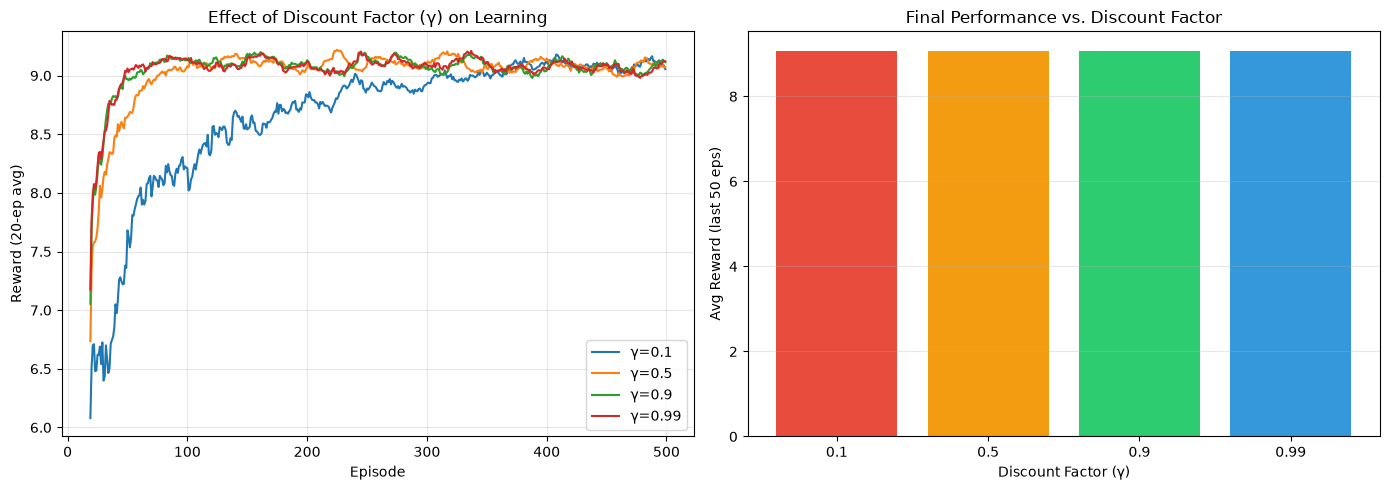

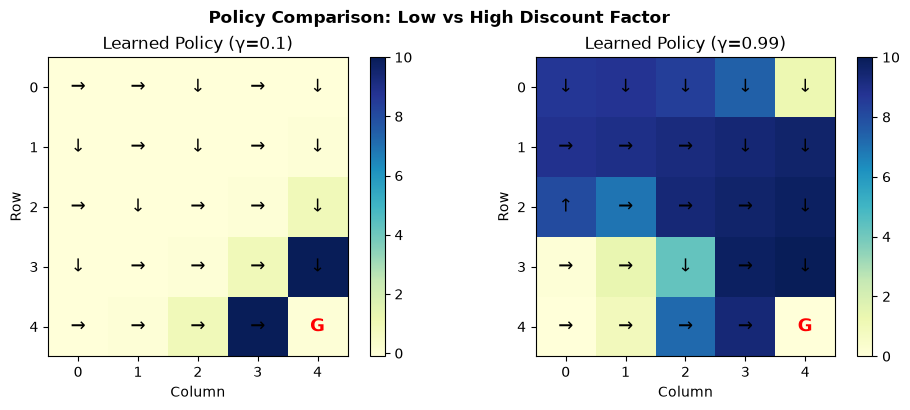

γ=0.1  →  Avg reward (last 50 eps): 9.068
γ=0.5  →  Avg reward (last 50 eps): 9.058
γ=0.9  →  Avg reward (last 50 eps): 9.076
γ=0.99  →  Avg reward (last 50 eps): 9.060


In [5]:
gammas = [0.1, 0.5, 0.9, 0.99]
n_episodes = 500
window = 20

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
gamma_avg_rewards = []

for gamma in gammas:
    np.random.seed(0)
    Q_g, rewards_g = q_learning(gamma=gamma, n_episodes=n_episodes)
    smoothed = np.convolve(rewards_g, np.ones(window) / window, mode='valid')
    axes[0].plot(range(window - 1, n_episodes), smoothed, label=f'γ={gamma}')
    gamma_avg_rewards.append(np.mean(rewards_g[-50:]))

axes[0].set_xlabel('Episode')
axes[0].set_ylabel(f'Reward ({window}-ep avg)')
axes[0].set_title('Effect of Discount Factor (γ) on Learning')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].bar([str(g) for g in gammas], gamma_avg_rewards,
            color=['#e74c3c', '#f39c12', '#2ecc71', '#3498db'])
axes[1].set_xlabel('Discount Factor (γ)')
axes[1].set_ylabel('Avg Reward (last 50 eps)')
axes[1].set_title('Final Performance vs. Discount Factor')
axes[1].grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.show()

# Policy grid comparison: low vs high gamma
fig, axes2 = plt.subplots(1, 2, figsize=(10, 4))
for ax, g in zip(axes2, [0.1, 0.99]):
    np.random.seed(0)
    Q_g, _ = q_learning(gamma=g, n_episodes=n_episodes)
    max_Q_g = np.max(Q_g, axis=2)
    best_act_g = np.argmax(Q_g, axis=2)
    im = ax.imshow(max_Q_g, cmap='YlGnBu')
    plt.colorbar(im, ax=ax)
    for r in range(GRID_SIZE):
        for c in range(GRID_SIZE):
            if (r, c) == GOAL:
                ax.text(c, r, 'G', ha='center', va='center',
                        fontsize=13, fontweight='bold', color='red')
            else:
                ax.text(c, r, ARROWS[best_act_g[r, c]],
                        ha='center', va='center', fontsize=13)
    ax.set_title(f'Learned Policy (γ={g})')
    ax.set_xlabel('Column')
    ax.set_ylabel('Row')

plt.suptitle('Policy Comparison: Low vs High Discount Factor', fontweight='bold')
plt.tight_layout()
plt.show()

for g, avg in zip(gammas, gamma_avg_rewards):
    print(f'γ={g}  →  Avg reward (last 50 eps): {avg:.3f}')


## Exercise 6: Policy Evaluation
Compare different settings using cumulative rewards, steps taken, and success rate.

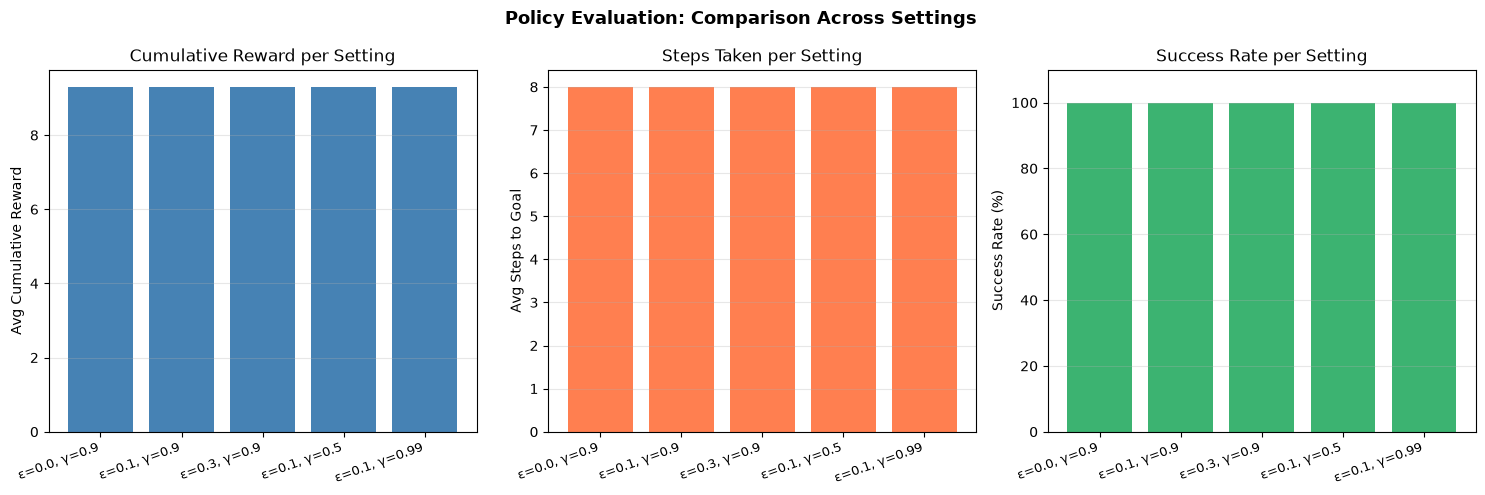

Setting                  Avg Reward   Avg Steps   Success Rate
--------------------------------------------------------------
ε=0.0, γ=0.9                  9.300        8.00         100.0%
ε=0.1, γ=0.9                  9.300        8.00         100.0%
ε=0.3, γ=0.9                  9.300        8.00         100.0%
ε=0.1, γ=0.5                  9.300        8.00         100.0%
ε=0.1, γ=0.99                 9.300        8.00         100.0%


In [6]:
def evaluate_policy(Q, n_eval=200, max_steps=100):
    """Evaluate greedy policy derived from Q. Returns avg reward, avg steps, success rate (%)."""
    total_rewards, total_steps, successes = [], [], 0
    for _ in range(n_eval):
        state = (0, 0)
        done = False
        ep_reward = 0
        steps = 0
        while not done and steps < max_steps:
            r, c = state
            action = int(np.argmax(Q[r, c]))
            state, reward, done = step(state, action)
            ep_reward += reward
            steps += 1
        total_rewards.append(ep_reward)
        total_steps.append(steps)
        if done and state == GOAL:
            successes += 1
    return np.mean(total_rewards), np.mean(total_steps), successes / n_eval * 100

settings = [
    {'label': 'ε=0.0, γ=0.9',  'epsilon': 0.0,  'gamma': 0.9},
    {'label': 'ε=0.1, γ=0.9',  'epsilon': 0.1,  'gamma': 0.9},
    {'label': 'ε=0.3, γ=0.9',  'epsilon': 0.3,  'gamma': 0.9},
    {'label': 'ε=0.1, γ=0.5',  'epsilon': 0.1,  'gamma': 0.5},
    {'label': 'ε=0.1, γ=0.99', 'epsilon': 0.1,  'gamma': 0.99},
]

results = []
for s in settings:
    np.random.seed(0)
    Q_s, _ = q_learning(epsilon=s['epsilon'], gamma=s['gamma'], n_episodes=500)
    avg_rew, avg_steps, succ = evaluate_policy(Q_s)
    results.append({'label': s['label'], 'avg_reward': avg_rew,
                    'avg_steps': avg_steps, 'success_rate': succ})

labels        = [r['label'] for r in results]
avg_rews      = [r['avg_reward'] for r in results]
avg_steps_lst = [r['avg_steps'] for r in results]
succ_rates    = [r['success_rate'] for r in results]

x = np.arange(len(labels))
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].bar(x, avg_rews, color='steelblue')
axes[0].set_xticks(x)
axes[0].set_xticklabels(labels, rotation=20, ha='right', fontsize=9)
axes[0].set_ylabel('Avg Cumulative Reward')
axes[0].set_title('Cumulative Reward per Setting')
axes[0].grid(True, alpha=0.3, axis='y')

axes[1].bar(x, avg_steps_lst, color='coral')
axes[1].set_xticks(x)
axes[1].set_xticklabels(labels, rotation=20, ha='right', fontsize=9)
axes[1].set_ylabel('Avg Steps to Goal')
axes[1].set_title('Steps Taken per Setting')
axes[1].grid(True, alpha=0.3, axis='y')

axes[2].bar(x, succ_rates, color='mediumseagreen')
axes[2].set_xticks(x)
axes[2].set_xticklabels(labels, rotation=20, ha='right', fontsize=9)
axes[2].set_ylabel('Success Rate (%)')
axes[2].set_ylim(0, 110)
axes[2].set_title('Success Rate per Setting')
axes[2].grid(True, alpha=0.3, axis='y')

plt.suptitle('Policy Evaluation: Comparison Across Settings',
             fontweight='bold', fontsize=13)
plt.tight_layout()
plt.show()

print(f'{"Setting":<22} {"Avg Reward":>12} {"Avg Steps":>11} {"Success Rate":>14}')
print('-' * 62)
for r in results:
    print(f"{r['label']:<22} {r['avg_reward']:>12.3f} "
          f"{r['avg_steps']:>11.2f} {r['success_rate']:>13.1f}%")
